Train the lab's U-Net from scratch on MNIST's
60,000 training digits, which you download,
for example with
torchvision.datasets.MNIST . For a
random 10% of examples, replace the label
with 10 ("no label"). Then sample with w = 0,
1, 2, 4.

In [1]:
import copy, time
import numpy as np, matplotlib.pyplot as plt, torch
from torchvision.datasets import MNIST
import mnist_guidance_lab as mg

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device", DEVICE)

evaluator = mg.Evaluator()
evaluator.load_state_dict(torch.load("evaluator.pt", map_location="cpu", weights_only=True)["state"])
evaluator = evaluator.to(DEVICE).eval().requires_grad_(False)

train_data = MNIST("data", train=True, download=True)
test_data = MNIST("data", train=False, download=True)

x_train = train_data.data.float() / 255 * 2 - 1
x_test = test_data.data.float() / 255 * 2 - 1

x_train = x_train.unsqueeze(1)
x_test = x_test.unsqueeze(1)

y_train = train_data.targets.long()
y_test = test_data.targets.long()

print(len(x_train), "training digits,", len(x_test), "test digits")
print(x_train.shape, x_train.min().item(), x_train.max().item())

device cuda


100%|█████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:00<00:00, 13.3MB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 436kB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:00<00:00, 3.86MB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 18.0MB/s]


60000 training digits, 10000 test digits
torch.Size([60000, 1, 28, 28]) -1.0 1.0


Step 5000: loss = 0.0634, time = 1.3 min
Step 10000: loss = 0.0615, time = 2.7 min
Step 15000: loss = 0.0603, time = 4.0 min
Step 20000: loss = 0.0599, time = 5.3 min
Step 25000: loss = 0.0593, time = 6.7 min
Step 30000: loss = 0.0591, time = 8.0 min


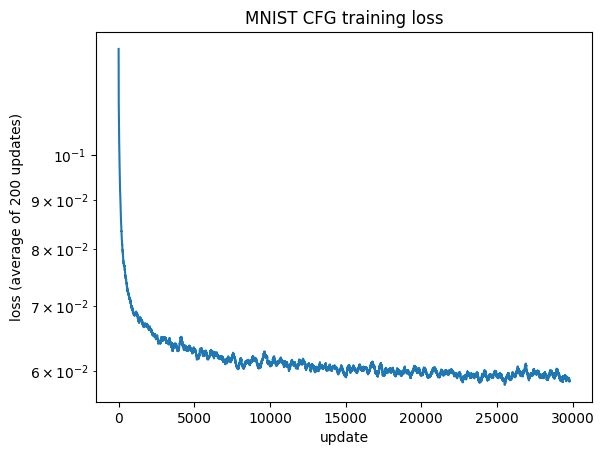

In [5]:
STEPS, BATCH = 30000, 128
LABEL_DROPOUT = 0.1 
NO_LABEL = 10 
torch.manual_seed(0)
net = mg.UNet(ch=64).to(DEVICE).train()
ema = copy.deepcopy(net).eval().requires_grad_(False)
opt = torch.optim.Adam(net.parameters(), lr=2e-4)
xs, ys = x_train.to(DEVICE), y_train.to(DEVICE)
losses, t0 = [], time.time()

for step in range(1, STEPS + 1):
    batch_indices = torch.randint(len(xs), (BATCH,), device=DEVICE)
    images = xs[batch_indices]
    labels = ys[batch_indices].clone()

    # replace 10% of labels with 10
    drop_mask = torch.rand(BATCH, device=DEVICE) < LABEL_DROPOUT
    labels[drop_mask] = NO_LABEL

    # add noise (x_t = alpha_t * x1 + sigma_t * x0)
    t = torch.rand(BATCH, device=DEVICE)
    alpha, sigma = mg.alpha_sigma(t[:, None, None, None])
    noise = torch.randn_like(images)
    noisy_images = alpha * images + sigma * noise

    # train
    predicted_images = net(noisy_images, t, labels)
    loss = ((predicted_images - images) ** 2).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()

    # update EMA
    decay = 0.9 if step <= 1000 else 0.999
    with torch.no_grad():
        for ema_param, model_param in zip(ema.parameters(), net.parameters()):
            ema_param.lerp_(model_param, 1 - decay)

    losses.append(loss.item())

    if step % 5000 == 0:
        avg_loss = np.mean(losses[-1000:])
        minutes = (time.time() - t0) / 60
        print(f"Step {step}: loss = {avg_loss:.4f}, time = {minutes:.1f} min")

torch.save({"state": ema.state_dict(), "ch": 64}, "mnist_cfg_unet.pt")

plt.plot(np.convolve(losses, np.ones(200) / 200, mode="valid"))
plt.yscale("log"); plt.xlabel("update"); plt.ylabel("loss (average of 200 updates)"); plt.title("MNIST CFG training loss")
plt.show()

w = 0, accuracy = 10.5%, FID = 58.01
w = 1, accuracy = 98.3%, FID = 7.11
w = 2, accuracy = 100.0%, FID = 63.70
w = 4, accuracy = 100.0%, FID = 140.77
Real test images: accuracy = 99.3%, FID = 5.58


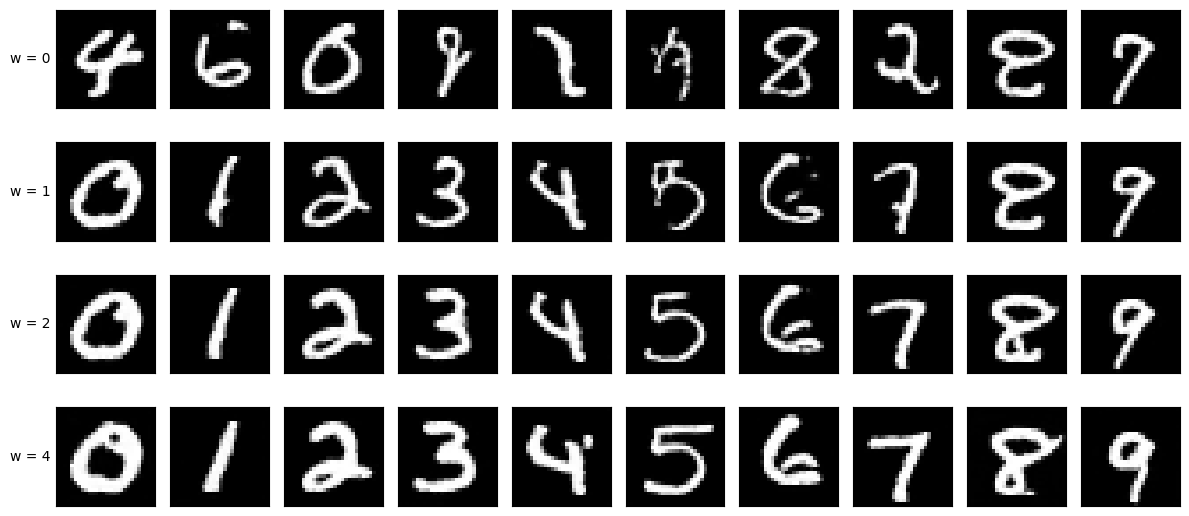

In [6]:
def feats(x):
    return torch.cat([evaluator.features(x[i:i + 1000].to(DEVICE)).double().cpu() for i in range(0, len(x), 1000)])

def gaussian(f):
    return f.mean(0), torch.cov(f.T)

def frechet(mu1, s1, mu2, s2):   # CIFAR-10 notebook FID formula
    e, V = torch.linalg.eigh(s1)
    r = V @ torch.diag(e.clamp(min=0).sqrt()) @ V.T
    m = r @ s2 @ r
    root_trace = torch.linalg.eigvalsh((m + m.T) / 2).clamp(min=0).sqrt().sum()
    return float(((mu1 - mu2) ** 2).sum() + s1.trace() + s2.trace() - 2 * root_trace)

real_mean, real_cov = gaussian(feats(x_train))
num_images = 10000
labels = torch.arange(num_images) % 10
samples = {}

for w in [0, 1, 2, 4]:
    images, _ = mg.sample(ema, num_images, labels, DEVICE, steps=16, w=float(w), seed=0, batch=1000)
    accuracy, _ = mg.classification(evaluator, images, labels, DEVICE) #accuracy
    features = feats(images) #FID
    mean, cov = gaussian(features)
    fid = frechet(mean, cov, real_mean, real_cov)

    print(f"w = {w}, accuracy = {accuracy:.1%}, FID = {fid:.2f}")
    samples[f"w = {w}"] = images

test_accuracy, _ = mg.classification(evaluator, x_test, y_test, DEVICE)
test_features = feats(x_test)
test_mean, test_cov = gaussian(test_features)
test_fid = frechet(test_mean, test_cov, real_mean, real_cov)
print(f"Real test images: accuracy = {test_accuracy:.1%}, FID = {test_fid:.2f}")

mg.grid(samples)